# Capture

**Written by Claude (Anthropic), 2026-10-25 12:44.** This is a notebook version of the write-up "Claude Capture 2610251224". The ideas are doc's, posited and up for testing. The words and code are Claude's, built on Codex's coiled ring (`ring.py`, `view.py`).

A motor's torque grows with its current, and its back-EMF grows with its speed. In the ideal motor model, the two constants that say so are one quantity: how much linked flux a radian of turning catches.

In [1]:
from dataclasses import replace

import numpy as np
from units import q
from ring import Ring, capture, follow_flux, add_forces, torque_about_shaft, winding, area_arrow
from capture_view import CaptureView, explore_capture, reading, sentences, TRIANGLE, EDGE_ON, TURN

view = CaptureView()

def clean(x):
    return round(x, 9) + 0.0     # no minus on a zero

## Two constants, one number

A motor datasheet gives each law its own constant: torque per amp, the torque constant K_t, in N·m/A; and back-EMF per angular velocity, the back-EMF constant K_e, in V·s/rad. With current, voltage, and speed counted the same way on both sides, the two come out equal. Their units already agree. This ledger keeps the radian as a unit, so a torque shows it too:

In [2]:
torque_constant = q(1, 'newton * meter / rad / ampere')
back_emf_constant = q(1, 'volt * second / rad')
print(f"torque constant:   {torque_constant.to('weber / rad'):~P}")
print(f"back-EMF constant: {back_emf_constant.to('weber / rad'):~P}")

torque constant:   1.0 Wb/rad
back-EMF constant: 1.0 Wb/rad


## Linkage, and what a turn catches

The flux an outside field threads through a coil is its flux linkage, λ, in webers. Turn the coil and its linkage changes. How much linked flux a radian of turning catches we'll call the **capture**, κ:

$$d\lambda = \kappa\, d\theta$$

One weber per radian we'll call a **catch**.

The ring: a wire goes once around a ring's hole and winds 25 times around its tube on the way. The centerline radius is R = 1 m and the tube radius is a = 0.2 m. It carries 2 A in a uniform 1 T field, and it turns on a shaft along a diameter.

Its angle counts from face-on, turning the ring's way about the shaft. The write-up counted turning toward alignment as positive, so every capture here reads with the opposite sign. A minus means the opposite of: −1.9 catch is a release of 1.9 Wb per radian.

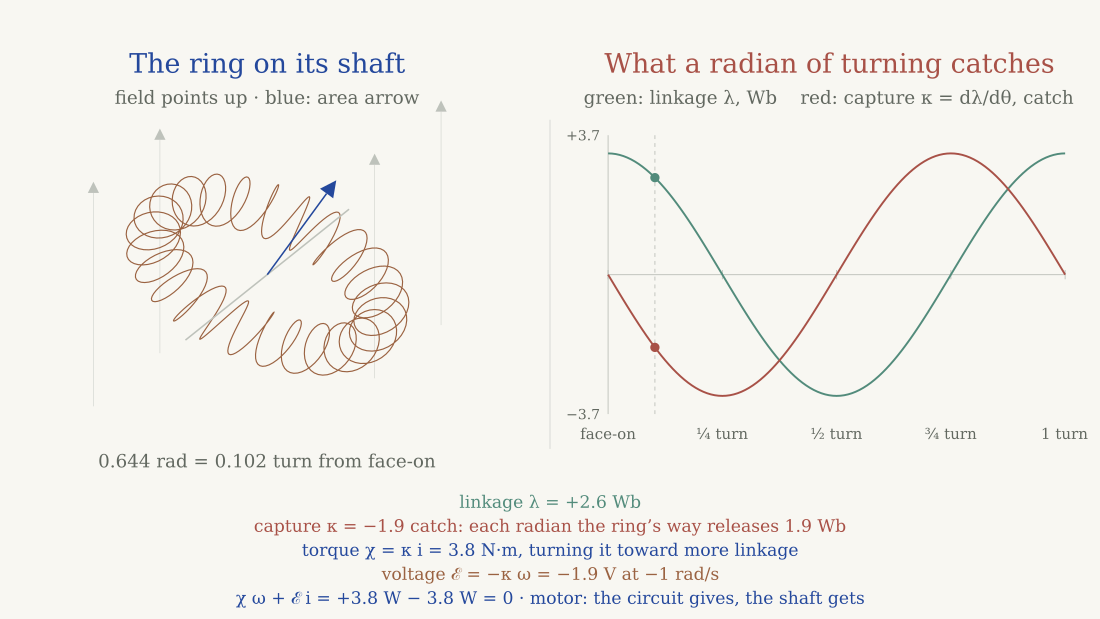

In [3]:
case = Ring(sweep=(-1, 'sweep'))     # turning toward face-on at 1 rad/s, as in the write-up
view.still(case, TRIANGLE)

Green is the linkage and red is the capture. They peak in opposite places. Face-on, the linkage is greatest and the capture is zero, because a small turn barely changes it. Edge-on, the linkage is zero, and each radian catches the whole face-on linkage. Linkage goes with the area arrow's forward part along the field, and capture goes with its upward part.

`capture` takes no differences. It dots the field with the way the area arrow sweeps about the shaft, B · (shaft × S). So a small turn makes an honest check:

In [4]:
dθ = 1e-5
dλ = follow_flux(case, TRIANGLE + dθ/2).linked - follow_flux(case, TRIANGLE - dθ/2).linked
print(f'dλ     = {dλ:+.6e} Wb')
print(f'κ dθ   = {capture(case, TRIANGLE)*dθ:+.6e} Wb')

dλ     = -1.922652e-05 Wb
κ dθ   = -1.922652e-05 Wb


## The two laws, a sentence each

Write the torque as χ, since τ has another job below. The capture of the current is the torque:

$$\chi = \kappa\, i$$

The voltage is the opposite of the capture of the angular velocity:

$$\mathcal{E} = -\kappa\, \omega$$

Together they're the machine's energy balance:

$$\chi\,\omega + \mathcal{E}\, i = 0$$

In [5]:
for line in sentences(case, reading(case, TRIANGLE)).values():
    print(line)

linkage λ = +2.6 Wb
capture κ = −1.9 catch: each radian the ring’s way releases 1.9 Wb
torque χ = κ i = 3.8 N·m, turning it toward more linkage
voltage ℰ = −κ ω = −1.9 V at −1 rad/s
χ ω + ℰ i = +3.8 W − 3.8 W = 0 · motor: the circuit gives, the shaft gets


Codex's ring also gets the torque without flux. It adds up I dr × B on every piece of all 25 windings, then their leverage about the shaft:

In [6]:
i = case.values['current']
for angle in [0, TRIANGLE, EDGE_ON, 2.8]:
    forces = torque_about_shaft(case, add_forces(case, angle).moment)
    print(f'{angle:5.3f} rad   forces {clean(forces):+.4f} N·m   capture of the current {clean(i*capture(case, angle)):+.4f} N·m')

0.000 rad   forces +0.0000 N·m   capture of the current +0.0000 N·m
0.644 rad   forces -3.8453 N·m   capture of the current -3.8453 N·m
1.571 rad   forces -6.4088 N·m   capture of the current -6.4088 N·m
2.800 rad   forces -2.1469 N·m   capture of the current -2.1469 N·m


Drive the shaft the other way, against its torque, and the same pose runs as a generator. The shaft gives, and the circuit gets:

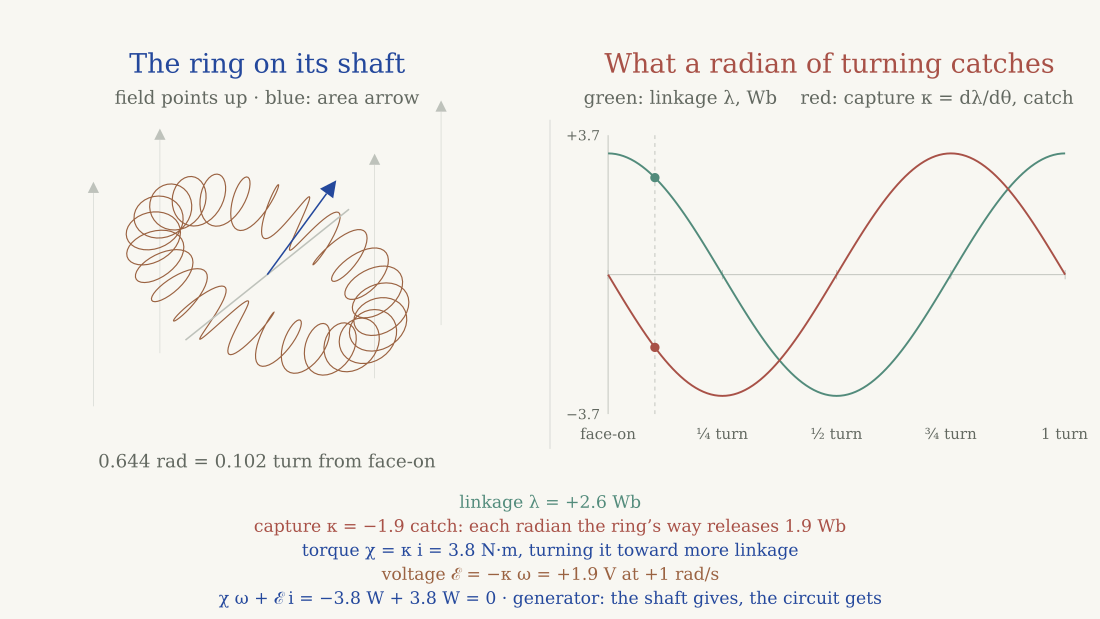

In [7]:
view.still(replace(case, sweep=(1, 'sweep')), TRIANGLE)

## A voltmeter measures it

Turn the ring at a known angular velocity and read the voltage. Here the voltmeter is the linkage's change over a short time. The opposite of the voltage, over the angular velocity, is the capture:

In [8]:
ω, dt = case.values['sweep'], 1e-5
for angle in [0, TRIANGLE, EDGE_ON]:
    before, after = (follow_flux(case, angle + ω*t).linked for t in (-dt/2, dt/2))
    voltage = -(after - before) / dt
    print(f'{angle:5.3f} rad   voltmeter {clean(voltage):+.4f} V   −ℰ/ω {clean(-voltage/ω):+.4f} catch   capture {clean(capture(case, angle)):+.4f} catch')

0.000 rad   voltmeter +0.0000 V   −ℰ/ω +0.0000 catch   capture +0.0000 catch
0.644 rad   voltmeter -1.9227 V   −ℰ/ω -1.9227 catch   capture -1.9227 catch
1.571 rad   voltmeter -3.2044 V   −ℰ/ω -3.2044 catch   capture -3.2044 catch


## Where the 3.2 Wb comes from

The linkage is the field times the area of the wire's shadow along the field. Call that area S here; A is already the amp's letter. The usual integral is π(R² + a²/2). Its 2π is the trip around the hole, written as two half-turns. Nothing in the ring gets flipped, so the halves are machinery this argument doesn't use.

Call all the way round one turn, τ. Going around the hole, each sliver of the shadow is a thin triangle, half of ρ by ρ dφ. A turn of slivers holds

$$S = \tfrac12\,\overline{\rho^2}\,\tau$$

where the bar means ρ² averaged over the turn. As the wire winds around the tube, it sways in and out by a times the forward part of its winding. The sway's square averages to a²/2.

In [9]:
points = winding(case)[0]                                  # sampled evenly around the hole
mean_square = np.mean(points[:, 0]**2 + points[:, 1]**2)   # ρ² averaged over the turn
print(f'ρ² averaged          {mean_square:.4f} m²    R² + a²/2 = {1 + .2**2/2:.4f} m²')
print(f'½ ρ² averaged · τ    {mean_square/2*TURN:.4f} m²')
print(f'shadow of the wire   {area_arrow(case)[2]:.4f} m²    (Codex’s signed triangles)')

ρ² averaged          1.0200 m²    R² + a²/2 = 1.0200 m²
½ ρ² averaged · τ    3.2044 m²
shadow of the wire   3.2044 m²    (Codex’s signed triangles)


The tube's size counts, through the a²/2. Slide the tube below and both curves grow with it. The 25 windings drop out because they're evenly spaced and the field is uniform.

## Turn it yourself

The angle slider turns the ring, and Play runs it once around. The ω slider sets the angular velocity the voltage and the balance are read at. From the 3–4–5 pose, negative ω turns it toward face-on, and it runs as a motor; positive ω drives it away, and it runs as a generator. The current can go negative too. The sliders need a running kernel.

In [10]:
explore_capture(case, view)

## Rocks on the trail

- Capture counts flux from an outside field. If the coil's own flux changes with angle too, as in a reluctance motor, the torque isn't the current times the whole rate, and that case takes coenergy.
- A motor's quoted constant describes its winding and commutation, averaged the way it runs. A bare ring's capture changes with its pose.